In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Assumptions – documented in Notion (Data Sources + Decision Log)
ASSUMPTIONS = {
    "ltv": 0.60,            # loan-to-value: share of the investment financed with loans (50–70 % for new projects)
    "bank_margin": 1.5,     # % added on top of the 5y mortgage bond rate = the developer's loan rate
    "equity_return": 6.0,   # % return the owners require on their own money
    "depreciation": 1.0,    # % per year – the building wears out over ~100 years
    "operating_cost": 450,  # kr/m²/year – running costs + maintenance (to verify)
}
ASSUMPTIONS

{'ltv': 0.6,
 'bank_margin': 1.5,
 'equity_return': 6.0,
 'depreciation': 1.0,
 'operating_cost': 450}

In [3]:
def break_even_rent(cost_per_m2, interest_rate, ltv, bank_margin,
                    equity_return, depreciation, operating_cost, subsidy_per_m2=0):
    """Rent per m² per year that a new rental building needs to cover all its costs."""
    investment = cost_per_m2 - subsidy_per_m2                     # what the owner actually pays
    loan_cost = investment * ltv * (interest_rate + bank_margin) / 100
    equity_cost = investment * (1 - ltv) * equity_return / 100
    depreciation_cost = investment * depreciation / 100
    return loan_cost + equity_cost + depreciation_cost + operating_cost

In [4]:
rent_low_rate  = break_even_rent(51000, 0.4, **ASSUMPTIONS)   # like 2021
rent_high_rate = break_even_rent(51000, 3.2, **ASSUMPTIONS)   # like 2026

print(f"Break-even rent at 0.4 %: {rent_low_rate:,.0f} kr/m²/year")
print(f"Break-even rent at 3.2 %: {rent_high_rate:,.0f} kr/m²/year")
print(f"For 55 m²: {rent_low_rate*55/12:,.0f} vs {rent_high_rate*55/12:,.0f} kr per month")

Break-even rent at 0.4 %: 2,765 kr/m²/year
Break-even rent at 3.2 %: 3,622 kr/m²/year
For 55 m²: 12,675 vs 16,602 kr per month


In [5]:
# Production cost for rentals (metro areas) × 1.05 Stockholm premium
price = pd.read_csv("../data/raw/scb_production_price_by_tenure.csv")
cost = price[
    (price["Region"] == "Storstadsområdena")
    & (price["Upplatform"] == "hyresrätt")
    & (price["BruttoNetto"] == "netto")
    & (price["ContentsCode"] == "Totalt produktionspris/lägenhetsarea, kr")
][["Tid", "value"]].rename(columns={"Tid": "year", "value": "cost"})
cost["cost"] = cost["cost"] * 1.05

# 2025 cost isn't published yet -> inflate 2024 with the construction cost index
idx = pd.read_csv("../data/raw/scb_construction_cost_index.csv")
idx["year"] = idx["Tid"].str[:4].astype(int)
idx = idx.groupby("year")["value"].mean()
cost_2025 = cost.loc[cost["year"] == 2024, "cost"].iloc[0] * idx[2025] / idx[2024]
cost = pd.concat([cost, pd.DataFrame({"year": [2025], "cost": [cost_2025]})])

# Interest rate: yearly average of the 5y mortgage bond
rates = pd.read_csv("../data/raw/riksbank_interest_rates_daily.csv", parse_dates=["date"])
rates["year"] = rates["date"].dt.year
bond_5y = rates[rates["series_id"] == "SEMB5YCACOMB"].groupby("year")["value"].mean()

# Actual rents in new rentals WITHOUT subsidy (presumtionshyra), Stor-Stockholm
rents = pd.read_csv("../data/raw/scb_rents_new_2022_onwards.csv")
actual = rents[
    (rents["Region"] == "Stor-Stockholm")
    & (rents["AntalRum"] == "Totalt")
    & (rents["ContentsCode"] == "årshyra per kvadratmeter, kr")
    & (rents["Hyresattningsmod"] == "Presumtionshyra")
][["Tid", "value"]].rename(columns={"Tid": "year", "value": "actual_rent"})

check = actual.merge(cost, on="year")
check

,year,actual_rent,cost
0,2022,2233.0,40220.250000
1,2023,2619.0,46243.050000
2,2024,2852.0,51210.600000
3,2025,3163.0,52536.126894


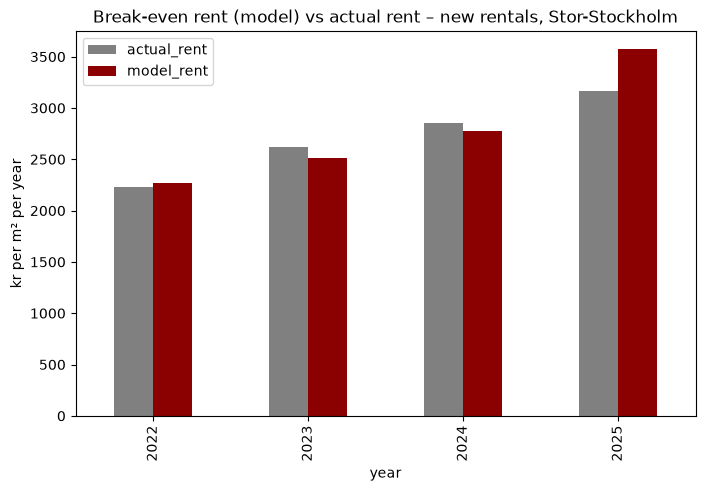

,year,actual_rent,cost,rate_used,model_rent,model_minus_actual
0,2022,2233.0,40220.25,0.37,2269.14,36.14
1,2023,2619.0,46243.05,0.26,2511.84,-107.16
2,2024,2852.0,51210.60,0.41,2777.44,-74.56
3,2025,3163.0,52536.13,2.74,3573.10,410.10


In [17]:
lag_years = 3  # the building was financed ~2 years before it was completed

check["rate_used"] = [bond_5y[y - lag_years] for y in check["year"]]
check["model_rent"] = [
    break_even_rent(c, r, **ASSUMPTIONS) for c, r in zip(check["cost"], check["rate_used"])
]
check["model_minus_actual"] = check["model_rent"] - check["actual_rent"]

ax = check.plot(x="year", y=["actual_rent", "model_rent"], kind="bar",
                figsize=(8, 5), color=["grey", "darkred"])
ax.set_title(f"Break-even rent (model) vs actual rent – new rentals, Stor-Stockholm")
ax.set_ylabel("kr per m² per year")
plt.show()
check.round(2)

In [18]:
check["model_minus_actual"].abs().mean()


np.float64(156.98948031529085)

In [19]:
# Investment subsidy per m² = gross price - net price (rentals, metro areas)
is_rental = price.eq("hyresrätt").any(axis=1)
is_metro  = price.eq("Storstadsområdena").any(axis=1)
is_total  = price.apply(lambda c: c.astype(str).str.startswith("Totalt")).any(axis=1)

subsidy = price[is_rental & is_metro & is_total].pivot_table(
    index="Tid", columns="BruttoNetto", values="value")
subsidy["subsidy_per_m2"] = subsidy["brutto"] - subsidy["netto"]
subsidy.tail(11)

BruttoNetto,brutto,netto,subsidy_per_m2
Tid,,,
2014,31172.0,31171.0,1.0
2015,31988.0,31981.0,7.0
2016,34375.0,34252.0,123.0
2017,36533.0,36297.0,236.0
2018,36677.0,36093.0,584.0
2019,37337.0,36628.0,709.0
2020,42312.0,42110.0,202.0
2021,40052.0,38927.0,1125.0
2022,39152.0,38305.0,847.0


In [22]:
row = check[check["year"] == 2025].iloc[0]
a = ASSUMPTIONS
gap = row["model_rent"] - row["actual_rent"]

# how much one kr of investment costs per year
capital_factor = (a["ltv"] * (row["rate_used"] + a["bank_margin"])
                  + (1 - a["ltv"]) * a["equity_return"] + a["depreciation"]) / 100

needed_subsidy = gap / capital_factor
needed_rate = row["rate_used"] - gap / (a["ltv"] * row["cost"] / 100)

max_subsidy = subsidy.loc[subsidy.index.astype(int).isin(range(2017, 2023)), "subsidy_per_m2"].max()
rent_with_old_subsidy = break_even_rent(row["cost"], row["rate_used"],
                                        subsidy_per_m2=max_subsidy, **ASSUMPTIONS)

print(f"Gap 2025: {gap:.0f} kr/m²/yr  (= {gap*55/12:.0f} kr/month for 55 m²)")
print(f"Subsidy needed to close the gap: {needed_subsidy:.0f} kr/m²")
print(f"Largest historical subsidy (SCB): {max_subsidy:.0f} kr/m²")
print(f"Break-even rent with that subsidy: {rent_with_old_subsidy:.0f} vs actual {row['actual_rent']:.0f}")
print(f"OR interest rate needed: {needed_rate:.2f} % (used: {row['rate_used']:.2f} %)")

Gap 2025: 410 kr/m²/yr  (= 1880 kr/month for 55 m²)
Subsidy needed to close the gap: 6899 kr/m²
Largest historical subsidy (SCB): 1125 kr/m²
Break-even rent with that subsidy: 3506 vs actual 3163
OR interest rate needed: 1.44 % (used: 2.74 %)


In [23]:
from pathlib import Path
out = Path("../data/processed"); out.mkdir(exist_ok=True)

# 1. Validation table (model vs actual)
check.to_csv(out / "validation.csv", index=False)

# 2. Subsidy history
subsidy.reset_index().to_csv(out / "subsidy_history.csv", index=False)

# 3. Scenario grid for Power BI sliders
BUILDING_COST = 41400
rows = []
for rate in [x / 4 for x in range(0, 21)]:                 # 0.00–5.00 %
    for sub in range(0, 8001, 500):                           # 0–8 000 kr/m²
        for land_name, land in [("Average", 11000), ("Suburb+", 20000),
                                ("Inner suburb", 30000), ("Inner city", 46000)]:
            rent = break_even_rent(BUILDING_COST + land, rate,
                                   subsidy_per_m2=sub, **ASSUMPTIONS)
            rows.append({"interest_rate": rate, "subsidy_per_m2": sub,
                         "location": land_name, "land_price": land,
                         "break_even_rent_m2": round(rent),
                         "monthly_rent_55m2": round(rent * 55 / 12)})
scenarios = pd.DataFrame(rows)
scenarios.to_csv(out / "scenarios.csv", index=False)
print(len(scenarios), "scenario rows saved")
scenarios.query("interest_rate == 2.75 and subsidy_per_m2 == 0")

1428 scenario rows saved


,interest_rate,subsidy_per_m2,location,land_price,break_even_rent_m2,monthly_rent_55m2
748,2.75,0,Average,11000,3568,16352
749,2.75,0,Suburb+,20000,4103,18807
750,2.75,0,Inner suburb,30000,4698,21534
751,2.75,0,Inner city,46000,5650,25897


In [26]:
inc = pd.read_csv("../data/raw/scb_disposable_income.csv")
inc = inc[inc.eq("Stockholms län").any(axis=1)]
inc = inc[inc["ContentsCode"] == "Medianvärde, tkr"]


# find the household-type column automatically
hh_col = next(c for c in inc.columns if not c.endswith("_code")
              and inc[c].astype(str).str.contains("ensamstående|sammanboende", case=False).any())
latest = inc["Tid"].max()

income = (inc[inc["Tid"] == latest][[hh_col, "value"]]
          .rename(columns={hh_col: "household", "value": "median_income_tkr"}))
income["monthly_income"] = (income["median_income_tkr"] * 1000 / 12).round()
print("Median disposable income, Stockholms län", latest)
display(income)

# combine every household type with every scenario
afford = scenarios.merge(income, how="cross")
afford["rent_share_pct"] = (afford["monthly_rent_55m2"] / afford["monthly_income"] * 100).round(1)
afford["affordable_30pct"] = afford["rent_share_pct"] <= 30
afford.to_csv(out / "affordability.csv", index=False)
print(len(afford), "rows saved")

afford.query("interest_rate == 2.75 and subsidy_per_m2 == 0 and location == 'Average'")[
    ["household", "monthly_income", "monthly_rent_55m2", "rent_share_pct", "affordable_30pct"]]

Median disposable income, Stockholms län 2024


,household,median_income_tkr,monthly_income
27,samtliga hushåll,551.5,45958.0
83,ensamstående utan barn,308.7,25725.0
139,ensamstående kvinnor utan barn,287.5,23958.0
195,ensamstående män utan barn,334.2,27850.0
251,ensamstående med barn 0–19 år,476.2,39683.0
307,ensamstående kvinnor med barn 0–19 år,451.6,37633.0
363,ensamstående män med barn 0–19 år,530.7,44225.0
419,ensamstående med kvarboende unga vuxna 20–29 år,616.8,51400.0
475,ensamstående kvinnor med kvarboende unga vuxna...,601.6,50133.0
531,ensamstående män med kvarboende unga vuxna 20–...,649.0,54083.0


21420 rows saved


,household,monthly_income,monthly_rent_55m2,rent_share_pct,affordable_30pct
11220,samtliga hushåll,45958.0,16352,35.6,False
11221,ensamstående utan barn,25725.0,16352,63.6,False
11222,ensamstående kvinnor utan barn,23958.0,16352,68.3,False
11223,ensamstående män utan barn,27850.0,16352,58.7,False
11224,ensamstående med barn 0–19 år,39683.0,16352,41.2,False
11225,ensamstående kvinnor med barn 0–19 år,37633.0,16352,43.5,False
11226,ensamstående män med barn 0–19 år,44225.0,16352,37.0,False
11227,ensamstående med kvarboende unga vuxna 20–29 år,51400.0,16352,31.8,False
11228,ensamstående kvinnor med kvarboende unga vuxna...,50133.0,16352,32.6,False
11229,ensamstående män med kvarboende unga vuxna 20–...,54083.0,16352,30.2,False


In [25]:
inc[inc["Tid"] == latest].head(2).T

,27,55
Region_code,1,1
Region,Stockholms län,Stockholms län
Hushallstyp_code,E90,E90
Hushallstyp,samtliga hushåll,samtliga hushåll
Alder_code,18+,18+
Alder,18+ år,18+ år
ContentsCode_code,000006SY,000006SZ
ContentsCode,"Medianvärde, tkr","Medianvärde, procent av samtliga hushåll"
Tid_code,2024,2024
Tid,2024,2024


In [27]:
raw = Path("../data/raw")

# 1. Completed dwellings by tenure + 5y bond rate (context page)
comp = pd.read_csv(raw / "scb_completed_dwellings_by_tenure.csv")
comp = comp[(comp["Region"] == "Stockholms län") & (comp["Hustyp_code"] == "FLERBO")]
comp = comp.pivot_table(index="Tid", columns="Upplatelseform", values="value").reset_index()

r = rates[rates["series_id"] == "SEMB5YCACOMB"].copy()
r["year"] = pd.to_datetime(r["date"]).dt.year
rate_year = r.groupby("year")["value"].mean().round(2).rename("bond_5y").reset_index()

context = comp.rename(columns={"Tid": "year"}).merge(rate_year, on="year", how="left")
context.to_csv(out / "completions_vs_rate.csv", index=False)

# 2. Land vs building cost over time (Stor-Stockholm, net)
pr = pd.read_csv(raw / "scb_production_price_by_region.csv")
pr = pr[(pr["Region"] == "Stor-Stockholm") & (pr["BruttoNetto"] == "netto")]
cost_split = pr.pivot_table(index="Tid", columns="ContentsCode", values="value").reset_index()
cost_split.to_csv(out / "cost_split.csv", index=False)

print(context.tail(), "\n")
print(cost_split.tail())

    year  bostadsrätt  hyresrätt  äganderätt  bond_5y
30  2021       5150.0     6997.0       102.0     0.41
31  2022       5127.0     5633.0       244.0     2.74
32  2023       6892.0     7797.0       240.0     3.69
33  2024       5630.0     6526.0       379.0     2.90
34  2025       3379.0     6169.0        60.0     2.73 

ContentsCode   Tid  Byggnadsobjekt, antal som prisstatistiken baseras på  \
26            2020                                               60.0      
27            2021                                               65.0      
28            2022                                               64.0      
29            2023                                               29.0      
30            2024                                               39.0      

ContentsCode  Byggnadspris/lägenhetsarea, kr  \
26                                   41257.0   
27                                   38877.0   
28                                   38431.0   
29                       

In [28]:
keep = {"Markpris/lägenhetsarea, kr": "land",
        "Byggnadspris/lägenhetsarea, kr": "building",
        "Totalt produktionspris/lägenhetsarea, kr": "total"}
cost_split = cost_split[["Tid"] + list(keep)].rename(columns={**keep, "Tid": "year"})
cost_split.to_csv(out / "cost_split.csv", index=False)
cost_split.tail()

ContentsCode,year,land,building,total
26,2020,15406.0,41257.0,56663.0
27,2021,14448.0,38877.0,53325.0
28,2022,13763.0,38431.0,52194.0
29,2023,12347.0,40161.0,52508.0
30,2024,14445.0,44383.0,58829.0
